# Model Training and Evaluation

The Titanic dataset is a binary classification problem where the objective is to predict passenger survival.

Multiple classification algorithms are trained and evaluated to identify the model that best generalizes to unseen data.

The following metrics are used for evaluation:

- Accuracy Score
- Precision Score
- Recall Score
- F1 Score

These metrics provide a comprehensive understanding of model performance and help select the most suitable algorithm.

In [2]:
# Basic Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
# Modelling
from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from sklearn.svm import SVC

from xgboost import XGBClassifier

from catboost import CatBoostClassifier

import warnings

C:\Users\gargi\AppData\Roaming\Python\Python39\site-packages\matplotlib\projections\__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Dataset Overview

The dataset has already been cleaned and transformed.

Target Variable:
- Survived

Features:
- Remaining engineered and encoded features

In [3]:
df = pd.read_csv("data/titanic_model_ready.csv")


In [4]:
df.head()


,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Sex_male,Embarked_Q,Embarked_S,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rare,Survived
0,3,-0.565736,0.432793,-0.473674,-0.502445,0.059160,0,True,False,True,False,False,False,True,False,False,False,0
1,1,0.663861,0.432793,-0.473674,0.786845,0.059160,0,False,False,False,False,False,False,False,True,False,False,1
2,3,-0.258337,-0.474545,-0.473674,-0.488854,-0.560975,1,False,False,True,True,False,False,False,False,False,False,1
3,1,0.433312,0.432793,-0.473674,0.420730,0.059160,0,False,False,True,False,False,False,False,True,False,False,1
4,3,0.433312,-0.474545,-0.473674,-0.486337,-0.560975,1,True,False,True,False,False,False,True,False,False,False,0


In [5]:
# Features and Target

X = df.drop(columns=["Survived"])
y = df["Survived"]

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
X_train.shape,X_test.shape

((712, 17), (179, 17))

#### Create an Evaluate Function to give all metrics after model Training

In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def evaluate_model(true, predicted):

    accuracy = accuracy_score(true, predicted)

    precision = precision_score(true, predicted)

    recall = recall_score(true, predicted)

    f1 = f1_score(true, predicted)

    return accuracy, precision, recall, f1

# Train the model with different models:


In [9]:
models = {

    "Logistic Regression":
        LogisticRegression(max_iter=1000),

    "K-Neighbors Classifier":
        KNeighborsClassifier(),

    "Decision Tree":
        DecisionTreeClassifier(random_state=42),

    "Random Forest":
        RandomForestClassifier(random_state=42),

    "Extra Trees":
        ExtraTreesClassifier(random_state=42),

    "Gradient Boosting":
        GradientBoostingClassifier(random_state=42),

    "AdaBoost":
        AdaBoostClassifier(random_state=42),

    "XGBoost":
        XGBClassifier(
            random_state=42,
            eval_metric='logloss'
        ),

    "CatBoost":
        CatBoostClassifier(
            verbose=False,
            random_state=42
        ),

    "SVC":
        SVC()
}
    

In [19]:
model_list = []

accuracy_list = []
precision_list = []
recall_list = []
f1_list = []

for i in range(len(list(models))):

    model = list(models.values())[i]

    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)

    y_test_pred = model.predict(X_test)

    (
        train_accuracy,
        train_precision,
        train_recall,
        train_f1
    ) = evaluate_model(y_train, y_train_pred)

    (
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ) = evaluate_model(y_test, y_test_pred)

    model_name = list(models.keys())[i]

    model_list.append(model_name)

    accuracy_list.append(test_accuracy)
    precision_list.append(test_precision)
    recall_list.append(test_recall)
    f1_list.append(test_f1)

    print(model_name)

    print("Model performance for Training set")
    print("- Accuracy: {:.4f}".format(train_accuracy))
    print("- Precision: {:.4f}".format(train_precision))
    print("- Recall: {:.4f}".format(train_recall))
    print("- F1 Score: {:.4f}".format(train_f1))

    print("----------------------------------")

    print("Model performance for Test set")
    print("- Accuracy: {:.4f}".format(test_accuracy))
    print("- Precision: {:.4f}".format(test_precision))
    print("- Recall: {:.4f}".format(test_recall))
    print("- F1 Score: {:.4f}".format(test_f1))

    print("=" * 35)
    print("\n")

Logistic Regression
Model performance for Training set
- Accuracy: 0.8371
- Precision: 0.8065
- Recall: 0.7463
- F1 Score: 0.7752
----------------------------------
Model performance for Test set
- Accuracy: 0.8045
- Precision: 0.7671
- Recall: 0.7568
- F1 Score: 0.7619


K-Neighbors Classifier
Model performance for Training set
- Accuracy: 0.8638
- Precision: 0.8519
- Recall: 0.7724
- F1 Score: 0.8102
----------------------------------
Model performance for Test set
- Accuracy: 0.8045
- Precision: 0.7826
- Recall: 0.7297
- F1 Score: 0.7552


Decision Tree
Model performance for Training set
- Accuracy: 0.9817
- Precision: 0.9961
- Recall: 0.9552
- F1 Score: 0.9752
----------------------------------
Model performance for Test set
- Accuracy: 0.7821
- Precision: 0.7465
- Recall: 0.7162
- F1 Score: 0.7310


Random Forest
Model performance for Training set
- Accuracy: 0.9817
- Precision: 0.9885
- Recall: 0.9627
- F1 Score: 0.9754
----------------------------------
Model performance for Tes

# Create the comparison Table to compair the models

In [21]:
results_df = pd.DataFrame({
    "Model Name": model_list,
    "Accuracy": accuracy_list,
    "Precision": precision_list,
    "Recall": recall_list,
    "F1 Score": f1_list
})

results_df.sort_values(
    by="F1 Score",
    ascending=False
)
#highest f1 score help to find the best model as this one is classification model 
#because f1 balances precision and Recall


,Model Name,Accuracy,Precision,Recall,F1 Score
3,Random Forest,0.837989,0.800000,0.810811,0.805369
7,XGBoost,0.821229,0.791667,0.770270,0.780822
4,Extra Trees,0.810056,0.750000,0.810811,0.779221
8,CatBoost,0.821229,0.818182,0.729730,0.771429
9,SVC,0.815642,0.805970,0.729730,0.765957
6,AdaBoost,0.804469,0.760000,0.770270,0.765101
0,Logistic Regression,0.804469,0.767123,0.756757,0.761905
1,K-Neighbors Classifier,0.804469,0.782609,0.729730,0.755245
5,Gradient Boosting,0.804469,0.800000,0.702703,0.748201
2,Decision Tree,0.782123,0.746479,0.716216,0.731034


# Automatically Find the Best Model

In [22]:
best_model_index = np.argmax(f1_list)

print("Best Model:", model_list[best_model_index])

print("Best F1 Score:",
      f1_list[best_model_index])

Best Model: Random Forest
Best F1 Score: 0.8053691275167785


# Retrain Best Model for ROC-AUC

In [23]:
best_model = list(models.values())[best_model_index]

best_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

# Calculate ROC-AUC 

In [24]:
from sklearn.metrics import roc_auc_score

y_prob = best_model.predict_proba(X_test)[:,1]

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.9046975546975548


# ROC Curve

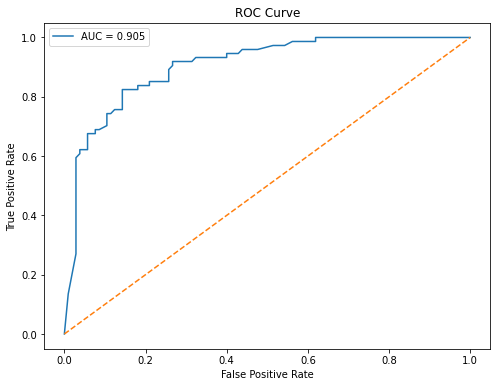

In [25]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()

plt.show()

## Model Selection

Multiple classification algorithms were evaluated using Accuracy, Precision, Recall, and F1 Score. The final model was selected based on the highest F1 Score, as it provides a balanced measure of both Precision and Recall.

The selected model was further evaluated using ROC-AUC Score to assess its ability to distinguish between passengers who survived and those who did not survive across various classification thresholds.


# Confusion Matrix

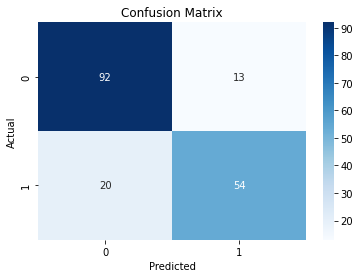

In [34]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_test_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

# Feature Importance

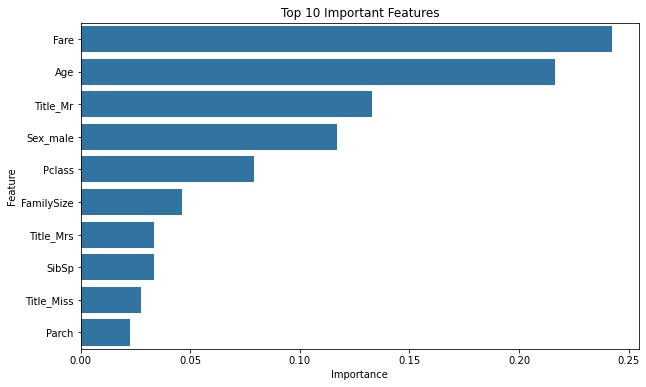

In [35]:
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")

plt.show()

# Conclusion

This project aimed to predict passenger survival on the Titanic using machine learning classification techniques. After performing data cleaning, feature engineering, preprocessing, and model evaluation, multiple classification algorithms were compared to identify the most effective model.

Among all evaluated models, the Random Forest Classifier achieved the highest prediction accuracy of approximately 83.8%, demonstrating strong generalization performance on unseen test data.

The Confusion Matrix shows that:
- 92 non-survivors were correctly classified.
- 54 survivors were correctly classified.
- Only 33 passengers were misclassified overall.

The ROC-AUC score of 0.905 indicates excellent classification performance and strong ability to distinguish between surviving and non-surviving passengers. Since the AUC value is significantly higher than 0.5 and close to 1.0, the model demonstrates excellent discriminatory power.

Feature importance analysis revealed that Fare, Age, Passenger Title, Gender, and Passenger Class were the most influential factors affecting survival prediction. This aligns with historical insights from the Titanic disaster, where socioeconomic status, age, and gender played major roles in survival outcomes.

Overall, the Random Forest Classifier proved to be a robust and reliable model for predicting passenger survival and successfully captured the key patterns present in the dataset.

## Actual vs Predicted Comparison

The table below presents a sample comparison between the actual survival outcomes and the model's predicted outcomes for selected passengers from the test dataset.

This comparison provides a quick validation of the model's prediction capability by highlighting whether the predicted class matches the true class. Correct predictions indicate successful classification, while mismatches represent areas where the model could potentially be improved.

The majority of predictions align with the actual outcomes, demonstrating that the model has learned meaningful patterns from the dataset and performs well on unseen data.

In [40]:
pred_df = pd.DataFrame({
    'Actual Value': y_test,
    'Predicted Value': y_test_pred
})

pred_df['Prediction Status'] = np.where(
    pred_df['Actual Value'] == pred_df['Predicted Value'],
    'Correct',
    'Incorrect'
)

pred_df

,Actual Value,Predicted Value,Prediction Status
709,1,0,Incorrect
439,0,0,Correct
840,0,0,Correct
720,1,1,Correct
39,1,1,Correct
...,...,...,...
433,0,0,Correct
773,0,0,Correct
25,1,0,Incorrect
84,1,1,Correct
